# 01 · Data exploration and splits

The dataset is **"A Sentiment Analysis Dataset for the Algerian Dialect of Arabic"** (Benmounah et al., 2023): 50,016 comments from Algerian YouTube channels, each labelled by hand as negative, neutral or positive. It is on the Hub as [`Abdou/dz-sentiment-yt-comments`](https://huggingface.co/datasets/Abdou/dz-sentiment-yt-comments) under the MIT licence.

Before training anything I want to know:
1. how the labels are balanced,
2. how much of the data is in Latin script (Arabizi) and how much is in Arabic script,
3. how long the comments are, which sets `max_length` for the LLM,
4. whether there are duplicates that could leak between train and test.

This notebook also creates the fixed 80/10/10 split that every other notebook uses.

> ⚠️ The data is raw YouTube comments, so some examples contain insults and swear words.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd
from transformers import AutoTokenizer

from darija_sentiment.config import BASE_MODEL, LABELS
from darija_sentiment.data import (
    build_clean_dataset, clean_text, detect_script, load_raw, make_splits, normalize_for_ngrams, save_splits,
)
from darija_sentiment.metrics import save_figure

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

## Raw data

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(50016, 2)


,text,label
0,يا سي كريم الرئيس الذى تشتكى له هو أصله معين,1
1,حتى السعودية قاتلكم ماكمش عرب،واش بقا يا بعاصيص باش ترجعو لأصلكم الأمازيغي..اتفووووو,0
2,Thbliiii bravo souade,2
3,تحيالي ناس بن يزقن و لقصور في الغيبة 🌹🇩🇿🤣,2
4,انتم اغبياء او تتغابوا هي تتكلم بالانجليزية و اضفتوا ترجم,0


In [3]:
raw["label"].map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3)

label
positive    0.437
negative    0.341
neutral     0.223
Name: proportion, dtype: float64

The classes are unbalanced: positive 44%, negative 34%, neutral 22%. That is why the headline metric is **macro-F1**, the unweighted mean of the three per-class F1 scores. A model that never predicts "neutral" can still get decent accuracy, but its macro-F1 drops.

## Duplicates

Short stock comments such as "روعة" (*amazing*), "top" or "rabi yarhmou" (*may God have mercy on him*) can appear many times. If the same string lands in both train and test, the test score partly measures memorisation. I deduplicate on a normalised key, so spelling variants like `رووعه` and `روعة` count as one comment.

In [4]:
key = raw["text"].map(clean_text).map(normalize_for_ngrams)
dup_groups = raw.groupby(key)["label"].agg(["size", "nunique"])
print("exact duplicates in raw text:   ", raw["text"].duplicated().sum())
print("duplicates after normalisation: ", (dup_groups["size"] - 1).sum())
print("normalised strings with conflicting labels:", (dup_groups["nunique"] > 1).sum())
dup_groups.sort_values("size", ascending=False).head(10)

exact duplicates in raw text:    0
duplicates after normalisation:  49
normalised strings with conflicting labels: 7


,size,nunique
text,,
رووعه,4,1
toop,3,1
foor,3,1
hh,3,2
فوورر,3,1
هه,3,2
الحمد لله,2,1
rabi yarhmou inchallah,2,2
ام وليد راكي غير تخلطي مشاهداتك بالملايرر راكي تدخلي ثلاثين مليار فالعام وانتي ديما حاصله فلبسه واحده متبدليهااش البخل ماشي مليح والناس راهم يعطوك الوصفاات ديري وصفات شابين ولكن انتي خبيثه وصفات ملاح دريهم فقناتك وفقناه سميره ديري وصفات تع خورطي,2,1


The dataset authors had already removed exact duplicates. Normalisation still finds **49 near-duplicates**, and 7 of those strings carry *conflicting* labels. `hh` and `rabi yarhmou inchallah` each have two different gold labels, an early sign that the annotations are not perfectly consistent. Conflicting copies are all dropped, because there is no way to know which label is right. In total this removes only 56 comments, so the cleaning matters more for correctness than for size.

In [5]:
df = build_clean_dataset()
print(f"{len(raw):,} raw → {len(df):,} after cleaning and de-duplication")
df.head()

50,016 raw → 49,960 after cleaning and de-duplication


,id,text,label,script
0,0,يا سي كريم الرئيس الذى تشتكى له هو أصله معين,1,arabic
1,1,حتى السعودية قاتلكم ماكمش عرب،واش بقا يا بعاصيص باش ترجعو لأصلكم الأمازيغي..اتفووووو,0,arabic
2,2,Thbliiii bravo souade,2,latin
3,3,تحيالي ناس بن يزقن و لقصور في الغيبة 🌹🇩🇿🤣,2,arabic
4,4,انتم اغبياء او تتغابوا هي تتكلم بالانجليزية و اضفتوا ترجم,0,arabic


## Arabic script vs. Latin script

Algerians write Darija in two scripts. Phones and keyboards made **Arabizi** common: Latin letters, with digits standing in for Arabic sounds that have no Latin letter (`3` = ع, `7` = ح, `9` = ق), as in *"ya3tik saha khoya"* (*well done, brother*). Code-switching with French is everywhere in both scripts.

`detect_script` assigns a comment to a script when at least 80% of its letters are in that script. Everything in between is `mixed`, and comments with no letters at all (emoji only) are `none`.

In [6]:
for text in ["ya3tik saha khoya", "ربي يحفظك", "bravo عليك خويا", "😂😂😂"]:
    print(f"{detect_script(text):>7}  {text}")

  latin  ya3tik saha khoya
 arabic  ربي يحفظك
  mixed  bravo عليك خويا
   none  😂😂😂


In [7]:
script_counts = df["script"].value_counts()
display(pd.DataFrame({"count": script_counts, "share": (script_counts / len(df)).round(3)}))
pd.crosstab(df["script"], df["label"].map(dict(enumerate(LABELS))), normalize="index").round(2)

,count,share
script,,
arabic,43054,0.862
latin,6323,0.127
mixed,499,0.010
none,84,0.002


label,negative,neutral,positive
script,,,
arabic,0.35,0.23,0.42
latin,0.29,0.17,0.55
mixed,0.17,0.39,0.44
none,0.11,0.36,0.54


About **13% of comments are Latin script**, so roughly 6,300 examples. That is enough to train on and to report a separate test score. Latin-script comments are more often positive (55% against 42%), so the label balance differs by script. The split is therefore stratified on *label × script*.

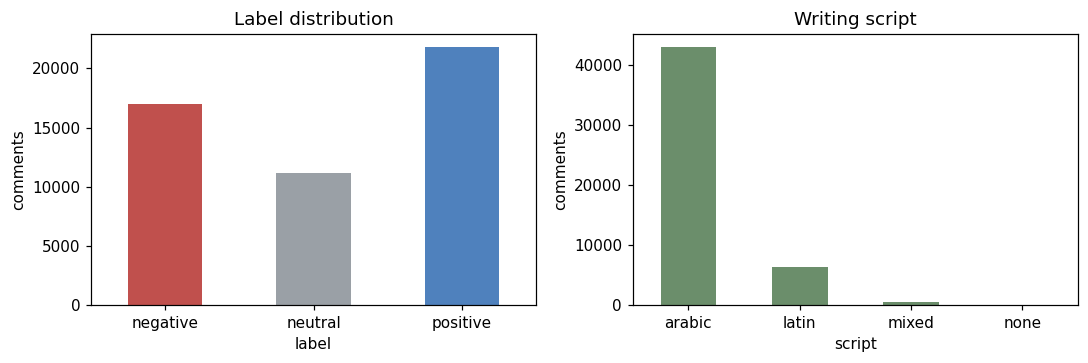

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
(df["label"].map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
   .plot.bar(ax=axes[0], color=["#c0504d", "#9aa0a6", "#4f81bd"], rot=0, title="Label distribution"))
script_counts.plot.bar(ax=axes[1], color="#6b8e6b", rot=0, title="Writing script")
for ax in axes:
    ax.set_ylabel("comments")
fig.tight_layout()
save_figure(fig, "data_distribution")

A few random examples per script and label, to get a feel for the data:

In [9]:
for script in ["arabic", "latin"]:
    for label_id, label in enumerate(LABELS):
        sample = df[(df["script"] == script) & (df["label"] == label_id)]["text"].sample(3, random_state=0)
        print(f"--- {script} / {label}")
        for t in sample:
            print("   ", t[:140])

--- arabic / negative
    عادت السرقة إلى الجزائر وغادرت ألمانيا
    ماجر يحكم في أخته قبل مايحكم على الفريق الوطني ياشراك فمك الفريق الوطني كبير عليك
    أنتا عميل. لي سليمان و أبوه. الموخنز
--- arabic / neutral
    و لي يحب يشارك فالموسم الثاني كفاش يدير😭😭😭😭😭😭😭
    ونرهب عدونا وعدوالله ............المغرب اسراييل فرنسا
    واش هو دور دقيق لرطب
--- arabic / positive
    فووووورخو❤❤
    ربي يكون في عونك وحنى معاك وبربي نشاله نحيو الخماج من البلاد
    حاجة شابة، بدينا نتقدمو شوية
--- latin / negative
    000000 ta9adim
    Ya chorfi anwaklou 3alik rabi !!! L'histoire et le peuple temoignera devant dieu de vos crimes .
    Pack de 💩💩💩💩 et de air zebel
--- latin / neutral
    Bach mrida atika???
    mab9a wlw nchlh
    dir da3me l9anawate
--- latin / positive
    Allh ybarek fel islab
    Hhhhhh bon courage
    Salem aleykoum oukhti Naïma h’louwa h’louwa y’attik. Allef saha. Oukhti saha f’tourkoum Salem


Some labels are debatable even in this small sample. "ونرهب عدونا وعدوالله… المغرب اسراييل فرنسا" (*we will terrify our enemy and God's enemy… Morocco, Israel, France*) is labelled **neutral** although it is openly hostile. Many neutral comments are questions ("Bach mrida atika???", *what is she sick with?*). The neutral class will probably be the hardest, both for the models and for the annotators.

## Comment length (in Qwen3 tokens)

          count  mean   std  min   50%   95%    99%     max
script                                                     
arabic  43054.0  31.6  41.6  1.0  22.0  84.0  167.0  2106.0
latin    6323.0  19.4  20.8  1.0  13.0  53.0   98.0   634.0
mixed     499.0  26.0  48.9  2.0  17.0  68.1  114.4   828.0
none       84.0  12.7  14.5  1.0   9.0  31.7   76.4    98.0


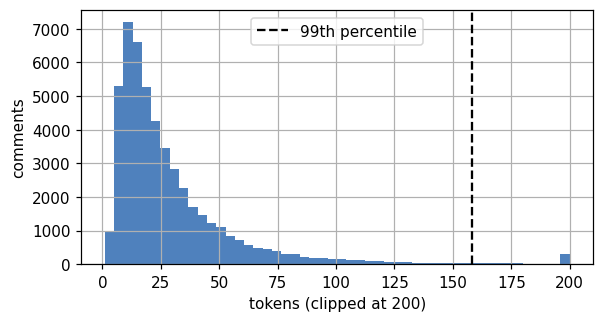

In [10]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
df["n_tokens"] = [len(ids) for ids in tokenizer(df["text"].tolist())["input_ids"]]
print(df.groupby("script")["n_tokens"].describe(percentiles=[0.5, 0.95, 0.99]).round(1))

fig, ax = plt.subplots(figsize=(6, 3))
df["n_tokens"].clip(upper=200).hist(bins=50, ax=ax, color="#4f81bd")
ax.axvline(df["n_tokens"].quantile(0.99), color="k", ls="--", label="99th percentile")
ax.set_xlabel("tokens (clipped at 200)")
ax.set_ylabel("comments")
ax.legend()
save_figure(fig, "token_lengths")

Most comments are short: the median is 22 tokens for Arabic script and 13 for Latin script, and the 99th percentile is 167 tokens. Truncating at **256 tokens** affects well under 1% of comments and keeps the GPU memory budget predictable. Latin-script comments are noticeably shorter, which leaves less context to judge sentiment from.

## Train / validation / test split

80/10/10, stratified on label × script, seed 42. The split is saved as CSV in `data/splits/`, and every notebook and script reads those same files.

- **train** is the only data any model learns from.
- **val** is used for model selection (TF-IDF regularisation, LoRA checkpoint).
- **test** is touched once per system, for the final numbers.

In [11]:
splits = make_splits(df.drop(columns="n_tokens"))
save_splits(splits)

summary = pd.DataFrame({
    name: {"size": len(part), **part["script"].value_counts().to_dict(),
           **part["label"].map(dict(enumerate(LABELS))).value_counts(normalize=True).round(3).to_dict()}
    for name, part in splits.items()
})
summary

,train,val,test
size,39968.000,4996.000,4996.000
arabic,34443.000,4305.000,4306.000
latin,5059.000,632.000,632.000
mixed,399.000,50.000,50.000
none,67.000,9.000,8.000
positive,0.436,0.436,0.437
negative,0.341,0.341,0.341
neutral,0.223,0.223,0.223
